# build dataframe from raw spectra, darknoise and powermeasurement

output a dataframe with:
- device
- label nm
- peak nm
- int_t_ms
- dark-corrected, spectrum, integrated over 1s
- dark-corrected power in nW

In [1]:
from pathlib import Path
import numpy as np
import pickle
import matplotlib.pyplot as plt
import pandas as pd

In [2]:
calib_folder = Path('/Users/dengyuyao/Github/SCAM/notebooks/ST_UV_calibration_01092026/')
raws_ = calib_folder / 'raw'
pkls_ = calib_folder / 'pkl'
darks_ = calib_folder / 'dark'

In [7]:
STUV_nm = np.load('/Users/dengyuyao/Github/SCAM/config/wavelength_STUV_100_03283.npy')
dark_power_nW = .4

## one eg running

### load the raw and darknoise

In [7]:
LED_name = 'LED_310nm_LED_peak310nm_200.0ms'
eg_spec = np.load(raws_ / f'{LED_name}.npy')
eg_dark = np.load(darks_ / f'{LED_name}_darknoise.npy')

### parse the name to get info

In [8]:
# parse the LED name and get the actual measured peak wavelength
peak_nm = int(LED_name.split('peak')[-1][:3])
device = LED_name.split('_')[0]
label_nm = int(LED_name.split('_')[1][:3])
int_t_ms = int(float(LED_name.split('_')[-1].strip('ms')))

device,label_nm,peak_nm,int_t_ms

('LED', 310, 310, 200)

### load the power from the pkl

In [24]:
dark_power_nW = .4
with open(pkls_ / f'{device}_{label_nm}nm_peak{peak_nm}.pkl', 'rb') as f:
    eg_power = pickle.load(f)
power_nW = eg_power['power']-.4

### apply dark correction

In [13]:
## apply darkcorrection
eg_spec_corr = np.mean(eg_spec-eg_dark,axis=0)
## convert the dark-corrected spectrum into integration time of 1 second
eg_spec_corr_s = eg_spec_corr/(int_t_ms/1e3)

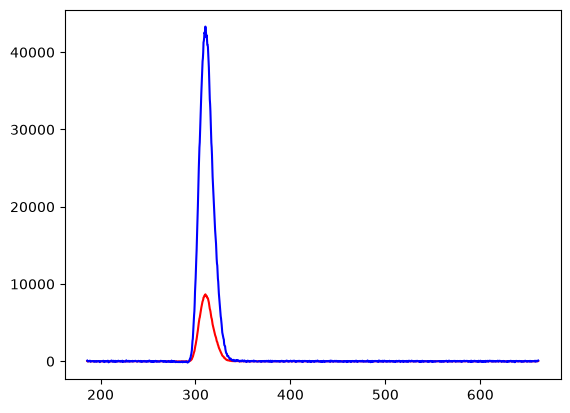

In [18]:
# viualize
plt.plot(STUV_nm,eg_spec_corr,color='red')
plt.plot(STUV_nm,eg_spec_corr_s,color='blue')

### build the data list for dataframe construction

In [25]:
col_list = ["device", 'label_nm', 'peak_nm', 'int_t_ms', 'spectrum_s_dark_corr','power_nW']
data_list=[]
#for led in os.listdir(data_folder):
led_info={}
led_info['device']=device
led_info['label_nm']=label_nm
led_info['peak_nm']=peak_nm
led_info['int_t_ms']=int_t_ms
led_info['spectrum_s_dark_corr']=eg_spec_corr_s
led_info['power_nW']=power_nW

data_list.append(led_info)

all_LEDs = pd.DataFrame(data_list, columns=col_list)
all_LEDs

,device,label_nm,peak_nm,int_t_ms,spectrum_s_dark_corr,power_nW
0,LED,310,310,200,"[85.0, 16.0, -36.0, 15.5, 28.999999999999996, ...",18.6


## loop through all the recorded file

In [4]:
import os

In [12]:
col_list = ["device", 'label_nm', 'peak_nm', 'int_t_ms', 'spectrum_s_dark_corr','power_nW']
data_list = []
for raw in sorted(raws_.glob('*.npy')):
    LED_name = raw.stem
    dark = darks_ / f'{LED_name}_darknoise.npy'
    if not dark.exists():
        continue
    # parse the name to get the info
    device = LED_name.split('_')[0]
    label_nm = int(LED_name.split('_')[1][:3])
    peak_nm = int(LED_name.split('peak')[-1][:3])
    int_t_ms = int(float(LED_name.split('_')[-1].strip('ms')))
    
    # load the power (pkl peak label can be off by a couple of nm -> take the closest)
    with open(pkls_ / f'{device}_{label_nm}nm_peak{peak_nm}.pkl', 'rb') as f:
        eg_power = pickle.load(f)
    power_nW = eg_power['power']-.4
    
    # apply dark correction and normalize to 1 s integration time
    spec_corr_s = np.mean(np.load(raw) - np.load(dark), axis=0) / (int_t_ms / 1e3)
    data_list.append({'device': device, 'label_nm': label_nm, 'peak_nm': peak_nm,
                      'int_t_ms': int_t_ms, 'spectrum_s_dark_corr': spec_corr_s,
                      'power_nW': power_nW})

all_LEDs = pd.DataFrame(data_list, columns=col_list)
all_LEDs

,device,label_nm,peak_nm,int_t_ms,spectrum_s_dark_corr,power_nW
0,LED,310,310,200,"[85.0, 16.0, -36.0, 15.5, 28.999999999999996, ...",18.60
1,LED,360,360,400,"[8.249999999999998, -13.0, -9.25, 17.749999999...",11.50
2,LED,360,362,250,"[18.4, -16.4, -33.2, 7.2, -9.6, -15.2, 2.8, -1...",19.50
3,LED,380,378,200,"[13.999999999999998, -37.0, 39.5, 40.999999999...",17.50
4,LED,380,379,50,"[226.0, 168.0, 387.99999999999994, 490.0, 190....",53.50
5,LED,393,392,100,"[-84.0, -159.0, -96.99999999999999, 57.9999999...",32.50
6,LED,400,400,50,"[233.99999999999997, 437.99999999999994, 91.99...",82.50
7,LED,400,402,150,"[-4.0, 3.3333333333333335, -74.0, -32.0, -74.0...",21.30
8,LED,430,428,150,"[-22.666666666666668, -47.333333333333336, -54...",32.80
9,LED,466,469,80,"[22.5, 256.25, 141.25, -38.75, -47.5, 26.25, 2...",80.40
